<div style="font-family:Times New Roman;font-size:14pt;color:black"><b>Лабораторна робота 8 додаткове завдання</b><br>Побудова рекомендаційної системи з нуля<br>Виконав Шиндир Олексій<br>4 курс, 10 група</div>

<a href="https://colab.research.google.com/github/raysewww-lang/mashynne-navchannia/blob/main/%D0%A8%D0%B8%D0%BD%D0%B4%D0%B8%D1%80_%D0%BF%D1%80_8_%D1%80%D0%B5%D0%BA%D0%BE%D0%BC%D0%B5%D0%BD%D0%B4%D0%B0%D1%86%D1%96%D1%97.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Відкрити в Colab"/></a>

In [1]:
# Підготовка бібліотек і даних. Дані автоматично завантажуються з GitHub; резервний спосіб — data.zip.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
np.random.seed(25)
plt.rcParams.update({'font.family':'serif','font.serif':['Times New Roman','DejaVu Serif'],'font.size':14,'figure.figsize':(9,5)})
pd.set_option('display.max_columns',40)

def data_path(name):
    for folder in [Path('data'),Path('.'),Path('/content/data'),Path('/content')]:
        p=folder/name
        if p.exists():
            return p
    import zipfile, io
    from urllib.request import urlopen
    try:
        url='https://raw.githubusercontent.com/raysewww-lang/mashynne-navchannia/main/data.zip'
        with urlopen(url, timeout=60) as response:
            content=response.read()
        Path('data').mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if not member.endswith('/'):
                    (Path('data')/Path(member).name).write_bytes(z.read(member))
        if (Path('data')/name).exists():
            return Path('data')/name
    except Exception as error:
        print('Автоматичне завантаження недоступне:',error)
    from google.colab import files
    import zipfile, io
    print('Завантажте data.zip або файл',name)
    uploaded=files.upload()
    Path('data').mkdir(exist_ok=True)
    for fname,content in uploaded.items():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(io.BytesIO(content)) as z:
                for member in z.namelist():
                    if not member.endswith('/'):
                        (Path('data')/Path(member).name).write_bytes(z.read(member))
        else:
            (Path('data')/Path(fname).name).write_bytes(content)
    p=Path('data')/name
    if not p.exists():
        raise FileNotFoundError(name)
    return p

In [2]:
# Завантажити MovieLens 100k. Побудувати системи МНК, градієнтного спуску та кластеризації.
ratings=pd.read_csv(data_path('u.data'),sep='	',names=['user','item','rating','timestamp'])
movies=pd.read_csv(data_path('u.item'),sep='|',encoding='latin-1',header=None,usecols=[0,1],names=['item','title'])
display(ratings.head());print(ratings.shape)
print('MovieLens 100k: https://grouplens.org/datasets/movielens/100k/')

from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
train,test=train_test_split(ratings,test_size=0.2,random_state=25)
nu=int(ratings.user.max());ni=int(ratings.item.max())
def matrix_from(frame):
    R=np.zeros((nu,ni),dtype=np.float64)
    R[frame.user.to_numpy()-1,frame.item.to_numpy()-1]=frame.rating
    return R
R=matrix_from(train)
mean=train.rating.mean()

,user,item,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


(100000, 4)
MovieLens 100k: https://grouplens.org/datasets/movielens/100k/


In [3]:
# Метод найменших квадратів. Матрична факторизація з почерговим розв’язанням регуляризованих задач МНК (ALS).
def als(R,k=12,reg=1.0,steps=8):
    rng=np.random.default_rng(25)
    P=rng.normal(0,0.1,(R.shape[0],k));Q=rng.normal(0,0.1,(R.shape[1],k))
    mask=R>0;mu=R[mask].mean();eye=np.eye(k)
    for _ in range(steps):
        for u in range(len(P)):
            idx=mask[u];A=Q[idx]
            P[u]=np.linalg.solve(A.T@A+reg*eye,A.T@(R[u,idx]-mu))
        for i in range(len(Q)):
            idx=mask[:,i];A=P[idx]
            Q[i]=np.linalg.solve(A.T@A+reg*eye,A.T@(R[idx,i]-mu))
    return np.clip(mu+P@Q.T,1,5)
als_pred=als(R)

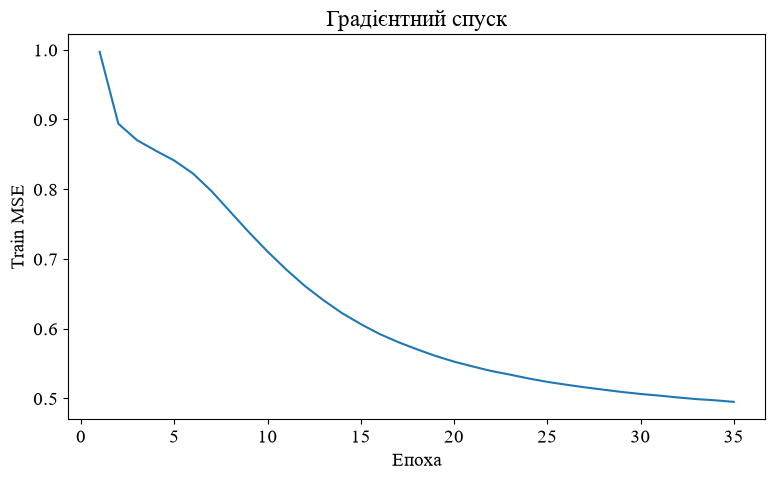

In [4]:
# Градієнтний спуск. Навчити приховані фактори та зміщення на відомих оцінках.
def gradient(R,k=12,lr=0.02,reg=0.05,epochs=35,batch=256):
    rng=np.random.default_rng(25);u,i=np.where(R>0);r=R[u,i];mu=r.mean()
    P=rng.normal(0,0.1,(R.shape[0],k));Q=rng.normal(0,0.1,(R.shape[1],k))
    bu=np.zeros(R.shape[0]);bi=np.zeros(R.shape[1]);loss=[]
    for _ in range(epochs):
        order=rng.permutation(len(r));total=0
        for start in range(0,len(r),batch):
            ix=order[start:start+batch];a=u[ix];b=i[ix]
            pu=P[a].copy();qi=Q[b].copy()
            error=r[ix]-(mu+bu[a]+bi[b]+np.sum(pu*qi,axis=1))
            np.add.at(P,a,lr*(error[:,None]*qi-reg*pu))
            np.add.at(Q,b,lr*(error[:,None]*pu-reg*qi))
            np.add.at(bu,a,lr*(error-reg*bu[a]))
            np.add.at(bi,b,lr*(error-reg*bi[b]))
            total+=np.sum(error**2)
        loss.append(total/len(r))
    return np.clip(mu+bu[:,None]+bi[None,:]+P@Q.T,1,5),loss
gd_pred,loss=gradient(R)
plt.plot(range(1,len(loss)+1),loss);plt.xlabel('Епоха');plt.ylabel('Train MSE');plt.title('Градієнтний спуск');plt.show()

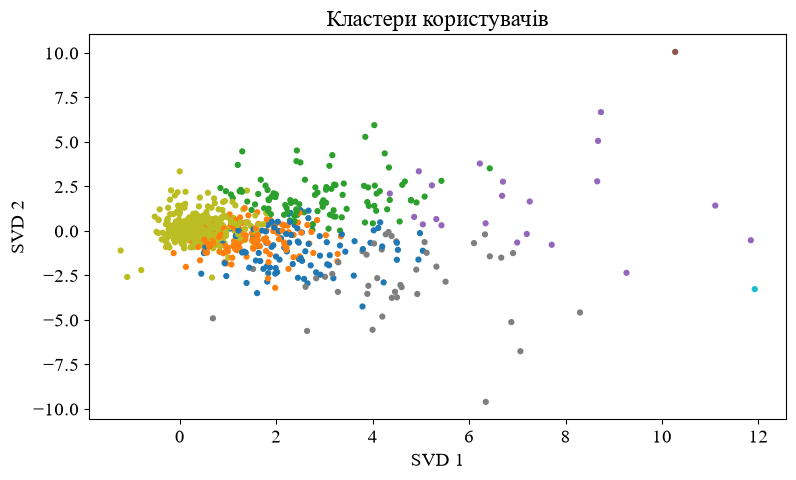

In [5]:
# Кластеризація користувачів. Прогноз із середніх оцінок кластерів зі згладжуванням.
def clustered(R,k=8):
    mask=R>0
    means=np.divide(R.sum(axis=1),mask.sum(axis=1),out=np.full(R.shape[0],3.0),where=mask.sum(axis=1)>0)
    centered=np.where(mask,R-means[:,None],0)
    features=TruncatedSVD(n_components=20,random_state=25).fit_transform(csr_matrix(centered))
    labels=KMeans(n_clusters=k,n_init=10,random_state=25).fit_predict(features)
    global_mean=R[mask].mean()
    item_mean=(R.sum(axis=0)+10*global_mean)/(mask.sum(axis=0)+10)
    cluster_means=[]
    for cl in range(k):
        rows=labels==cl
        cluster_means.append((R[rows].sum(axis=0)+5*item_mean)/(mask[rows].sum(axis=0)+5))
    return np.clip(np.asarray(cluster_means)[labels],1,5),labels,features
cluster_pred,labels,features=clustered(R)
plt.scatter(features[:,0],features[:,1],c=labels,cmap='tab10',s=12);plt.xlabel('SVD 1');plt.ylabel('SVD 2');plt.title('Кластери користувачів');plt.show()

In [6]:
# Оцінити три системи на однаковій тестовій вибірці. Вивести рекомендації користувачу 25.
rows=[]
for name,pred in [('МНК ALS',als_pred),('Градієнтний спуск',gd_pred),('Кластеризація',cluster_pred)]:
    p=pred[test.user.to_numpy()-1,test.item.to_numpy()-1]
    rows.append([name,np.mean(np.abs(test.rating-p)),np.sqrt(mean_squared_error(test.rating,p))])
results=pd.DataFrame(rows,columns=['Метод','MAE','RMSE']);display(results)
print('Найменша тестова MAE:',results.loc[results.MAE.idxmin(),'Метод'])
full_R=matrix_from(ratings)
final_predictions={'МНК ALS':als(full_R),'Градієнтний спуск':gradient(full_R)[0],'Кластеризація':clustered(full_R)[0]}
user_id=25;seen=set(ratings.loc[ratings.user==user_id,'item'])
for name,pred in final_predictions.items():
    candidates=movies.loc[~movies.item.isin(seen)].copy()
    candidates['Прогноз']=pred[user_id-1,candidates.item.to_numpy()-1]
    print(name);display(candidates.nlargest(10,'Прогноз'))

,Метод,MAE,RMSE
0,МНК ALS,0.794596,1.033824
1,Градієнтний спуск,0.733839,0.941325
2,Кластеризація,0.811182,1.015893


Найменша тестова MAE: Градієнтний спуск


МНК ALS


,item,title,Прогноз
288,289,Evita (1996),5.000000
318,319,Everyone Says I Love You (1996),5.000000
749,750,Amistad (1997),5.000000
957,958,To Live (Huozhe) (1994),5.000000
988,989,Cats Don't Dance (1997),5.000000
1008,1009,Stealing Beauty (1996),5.000000
1277,1278,Selena (1997),5.000000
1354,1355,Infinity (1996),5.000000
1128,1129,Chungking Express (1994),4.995636
278,279,Once Upon a Time... When We Were Colored (1995),4.943447


Градієнтний спуск


,item,title,Прогноз
1448,1449,Pather Panchali (1955),4.807108
962,963,Some Folks Call It a Sling Blade (1993),4.774368
222,223,Sling Blade (1996),4.768917
315,316,As Good As It Gets (1997),4.764914
1166,1167,"Sum of Us, The (1994)",4.734627
1018,1019,"Die xue shuang xiong (Killer, The) (1989)",4.729601
112,113,"Horseman on the Roof, The (Hussard sur le toit...",4.719907
866,867,"Whole Wide World, The (1996)",4.709575
118,119,Maya Lin: A Strong Clear Vision (1994),4.694948
612,613,My Man Godfrey (1936),4.682638


Кластеризація


,item,title,Прогноз
250,251,Shall We Dance? (1996),4.532583
512,513,"Third Man, The (1949)",4.490204
602,603,Rear Window (1954),4.457131
965,966,"Affair to Remember, An (1957)",4.449052
317,318,Schindler's List (1993),4.410539
482,483,Casablanca (1942),4.367082
1202,1203,Top Hat (1935),4.366917
706,707,Enchanted April (1991),4.364942
177,178,12 Angry Men (1957),4.362661
284,285,Secrets & Lies (1996),4.348178


In [7]:
# Висновок. З нуля реалізовано факторизацію ALS методом найменших квадратів, навчання факторів градієнтним спуском та кластерну систему. Відсутні рейтинги не використано як нульові відповіді. MAE і RMSE обчислено тільки для відкладених відомих оцінок. Після оцінки моделі перенавчено на всіх даних для рекомендацій користувачу 25.